
МОДЕЛЬ A + X = Y
Функционал         | Оценка     | Диапазон F >= 0                | F_max     
------------------------------------------------------------------------------------------
B.1, выборки       | -0.223755  | пусто                          | -0.999311 
B.2, моды          | -0.343079  | [-0.343139, -0.343018]         | 1.000000  
B.3, медианы K     | -0.343506  | [-0.343627, -0.343384]         | 1.000000  
B.4, медианы P     | -0.343506  | [-0.343627, -0.343384]         | 1.000000  

МОДЕЛЬ T * X = Y
Функционал         | Оценка     | Диапазон F >= 0                | F_max     
------------------------------------------------------------------------------------------
B.1, выборки       | -0.113289  | пусто                          | -0.999311 
B.2, моды          | -0.999289  | [-0.999643, -0.998935]         | 0.999289  
B.3, медианы K     | -0.985890  | [-0.986584, -0.985188]         | 0.985890  
B.4, медианы P     | -0.985890  | [-0.986584, -0.985188]         | 0.985890  


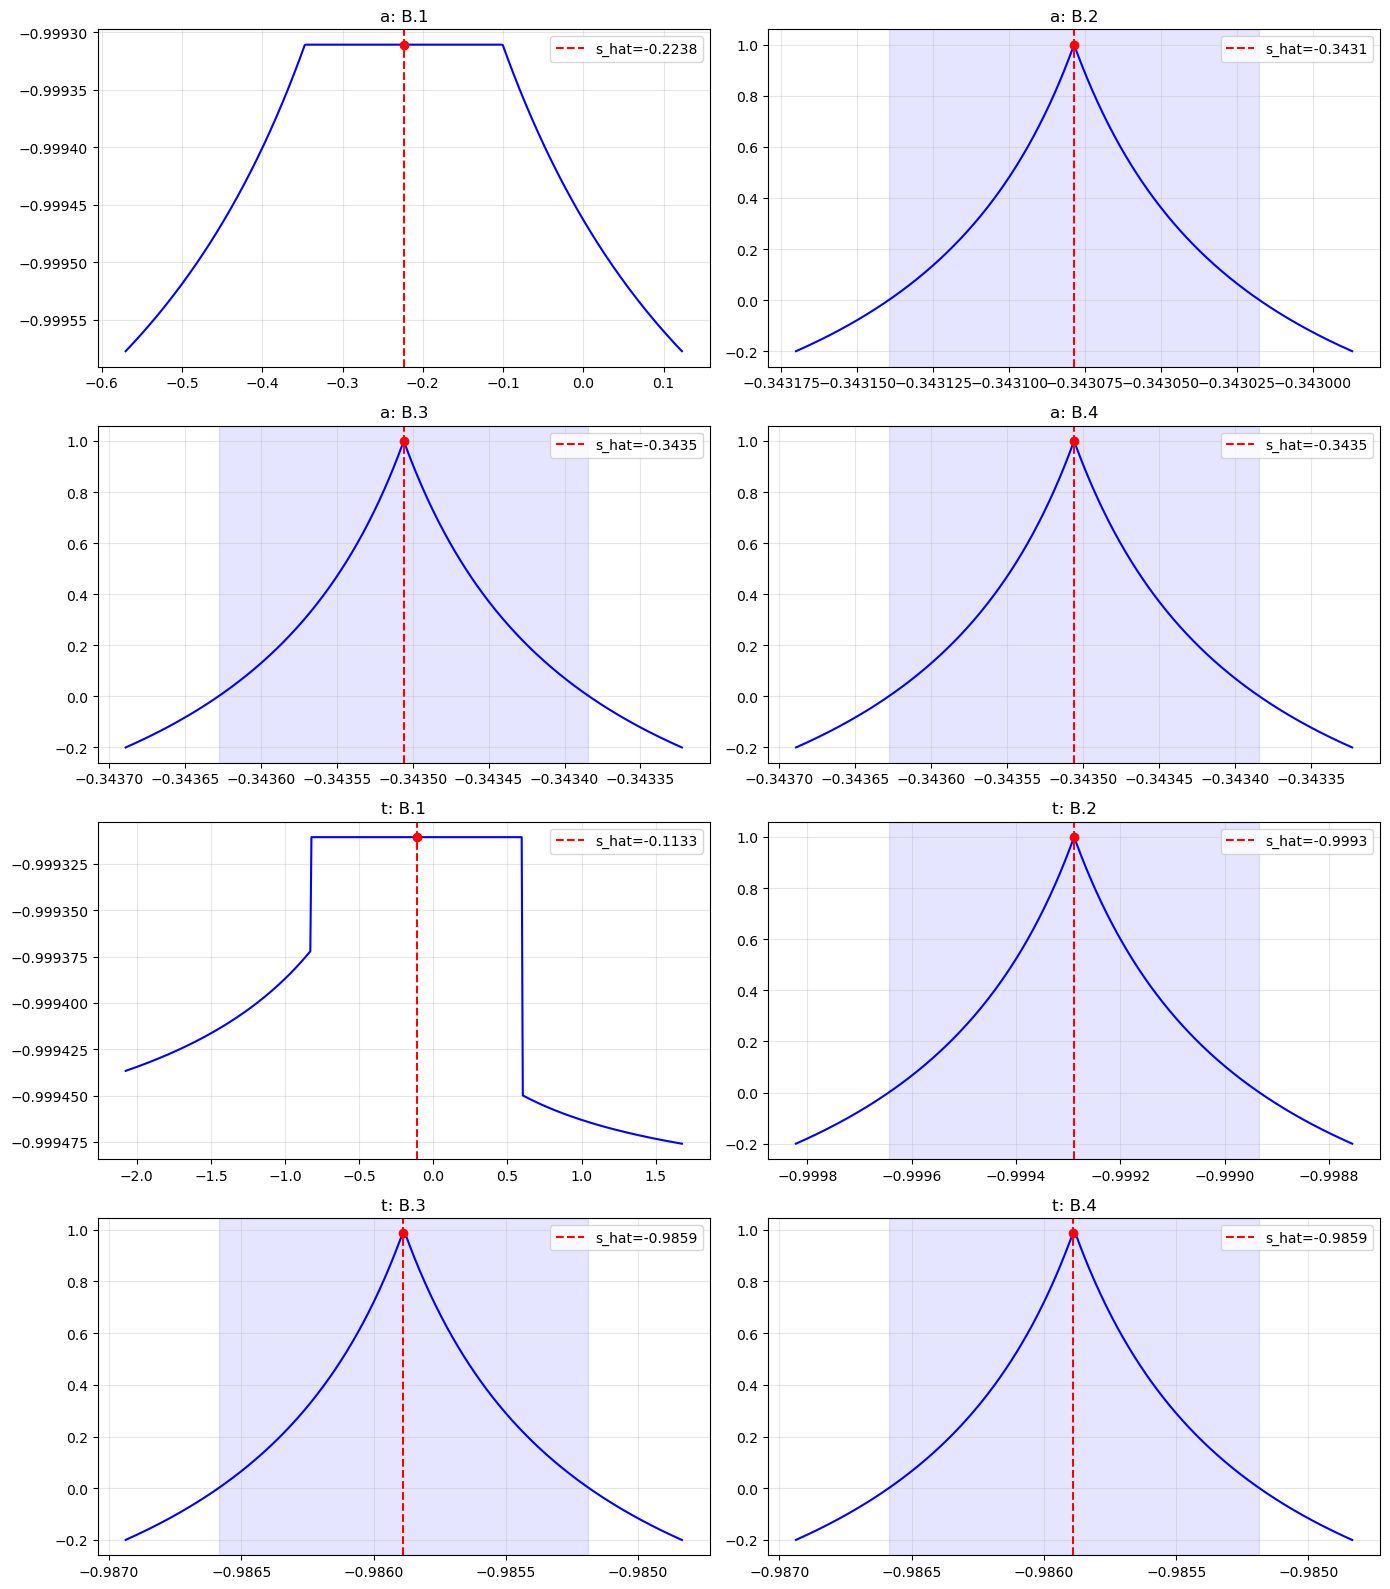

In [49]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

FILE_1 = Path("0.225_lvl_side_a_fast_data.bin")
FILE_2 = Path("-0.205_lvl_side_a_fast_data.bin")
RADIUS = 2**-14

TFileHeaderType = np.dtype([("side", "<u1"), ("mode", "<u1"), ("frame_count", "<u2"), ("reserved", "<u1", 252)])
TFrameHeaderType = np.dtype([("StopPoint", "u2"), ("TimeStamp", "u4"), ("reserved", "u2", 5)])
TMemoryPointType = np.dtype([("Data", "u2", 8)])
TMemoryFrameType = np.dtype([("Header", TFrameHeaderType), ("Point", TMemoryPointType, 1024)])

def process_file(filepath):
    frames = np.fromfile(filepath, dtype=TMemoryFrameType, offset=TFileHeaderType.itemsize)
    result = np.asarray(frames["Point"]["Data"], dtype=float)
    return (result / 16384 - 0.5).reshape(100, 1024*8)

def calc_wid(mid, rad):
    lo, hi = mid - rad, mid + rad
    inter_lo, inter_hi = lo.max(), hi.min()
    outer_lo, outer_hi = lo.min(), hi.max()
    return inter_hi - inter_lo, outer_hi - outer_lo

def calc_F(s, midX, radX, midY, radY, model="a"):
    if model == "a":
        midX = midX + s
    else:
        midX, radX = s * midX, abs(s) * radX
    mid = np.concatenate([np.ravel(midX), np.ravel(midY)])
    rad = np.concatenate([np.ravel(radX), np.ravel(radY)])
    inter, outer = calc_wid(mid, rad)
    return inter / outer

def calc_mode(mid, rad):
    lo, hi = np.ravel(mid - rad), np.ravel(mid + rad)
    ends = np.unique(np.concatenate([lo, hi]))
    count = np.searchsorted(np.sort(lo), ends[:-1], "right") - np.searchsorted(np.sort(hi), ends[:-1], "right")
    j = np.flatnonzero(count == count.max())
    mode_lo, mode_hi = ends[j[0]], ends[j[-1] + 1]
    return (mode_lo + mode_hi) / 2, (mode_hi - mode_lo) / 2

def calc_med_K(mid, rad):
    med_lo, med_hi = np.median(mid - rad), np.median(mid + rad)
    return (med_lo + med_hi) / 2, (med_hi - med_lo) / 2

def calc_med_P(mid, rad):
    return np.median(mid), np.median(rad)

def calc_grid(midX, radX, midY, radY, model):
    loX, hiX = np.min(midX - radX), np.max(midX + radX)
    loY, hiY = np.min(midY - radY), np.max(midY + radY)
    if model == "a":
        s_lo, s_hi = loY - hiX, hiY - loX
    else:
        ratios = np.outer([loY, hiY], 1 / np.array([loX, hiX]))
        s_lo, s_hi = ratios.min(), ratios.max()
    pad = (s_hi - s_lo) / 4
    return np.linspace(s_lo - pad, s_hi + pad, 501)  # 501 точка вместо 10^5

midX = process_file(FILE_1)
midY = process_file(FILE_2)
radX = np.full_like(midX, RADIUS)
radY = np.full_like(midY, RADIUS)

modeX = calc_mode(midX, radX)
modeY = calc_mode(midY, radY)
medK_X = calc_med_K(midX, radX)
medK_Y = calc_med_K(midY, radY)
medP_X = calc_med_P(midX, radX)
medP_Y = calc_med_P(midY, radY)

# Сразу создаем срезы для B.2-B.4 как массивы из 1 элемента
X_mode, R_mode = np.array([modeX[0]]), np.array([modeX[1]])
Y_mode, Ry_mode = np.array([modeY[0]]), np.array([modeY[1]])
X_medK, R_medK = np.array([medK_X[0]]), np.array([medK_X[1]])
Y_medK, Ry_medK = np.array([medK_Y[0]]), np.array([medK_Y[1]])
X_medP, R_medP = np.array([medP_X[0]]), np.array([medP_X[1]])
Y_medP, Ry_medP = np.array([medP_Y[0]]), np.array([medP_Y[1]])

# Собираем всё в словарь
cases = {
    "B.1": (midX, radX, midY, radY),
    "B.2": (X_mode, R_mode, Y_mode, Ry_mode),
    "B.3": (X_medK, R_medK, Y_medK, Ry_medK),
    "B.4": (X_medP, R_medP, Y_medP, Ry_medP),
}

results = {}
for model in ["a", "t"]:
    for case_name, (Xm, Xr, Ym, Yr) in cases.items():
        s = calc_grid(Xm, Xr, Ym, Yr, model)
        F = np.array([calc_F(si, Xm, Xr, Ym, Yr, model) for si in s])
        
        s_arg = s[F >= F.max() - 1e-12]
        s_cons = s[F >= 0]
        s_hat = (s_arg[0] + s_arg[-1]) / 2
        cons = (s_cons[0], s_cons[-1]) if s_cons.size else None
        
        results[(model, case_name)] = (s, F, s_hat, cons)

# --- КРАСИВЫЙ ВЫВОД ТАБЛИЦ ---
for model in ["a", "t"]:
    print(f"\n{'='*90}")
    print(f"МОДЕЛЬ {model.upper()} {'+ X = Y' if model == 'a' else '* X = Y'}")
    print(f"{'='*90}")
    print(f"{'Функционал':<18} | {'Оценка':<10} | {'Диапазон F >= 0':<30} | {'F_max':<10}")
    print("-" * 90)
    
    cases_names = {"B.1": "B.1, выборки", "B.2": "B.2, моды", "B.3": "B.3, медианы K", "B.4": "B.4, медианы P"}
    
    for case_name in ["B.1", "B.2", "B.3", "B.4"]:
        s, F, s_hat, cons = results[(model, case_name)]
        cons_str = f"[{cons[0]:.6f}, {cons[1]:.6f}]" if cons else "пусто"
        print(f"{cases_names[case_name]:<18} | {s_hat:<10.6f} | {cons_str:<30} | {F.max():<10.6f}")
    print("=" * 90)

# --- Графики ---
fig, axes = plt.subplots(4, 2, figsize=(14, 16))
axes = axes.flatten()

for i, (model, case_name) in enumerate(results.keys()):
    s, F, s_hat, cons = results[(model, case_name)]
    ax = axes[i]
    if cons:
        ax.axvspan(*cons, color='blue', alpha=0.1)
    ax.plot(s, F, color='blue')
    ax.axvline(s_hat, color='red', linestyle='--', label=f's_hat={s_hat:.4f}')
    ax.scatter([s_hat], [F.max()], color='red', zorder=5)
    ax.set_title(f"{model}: {case_name}")
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()